# 04 - A package from nothing

Write a package from an empty one: the coordinate reference systems, a horizon, and a
triangulated surface of that horizon with its points and triangles in HDF5. Then read it
back, judge it, and draw what was read - the only statement worth making about a write.

Nothing here needs a sample file.

```
pip install energyml-rust matplotlib pandas
```

In [1]:
import tempfile
import uuid
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from energyml.rust import model
from energyml.rust.epc import ArrayRef, Epc
from energyml.rust.resqml import mesh_of

## The model says what an object holds

The bridge carries the whole generated model of the standards. `describe` lists a class's
fields, which are required and of what type; `template` gives the smallest object of a class
to start from. Nobody has to remember the schema.

In [2]:
fields = pd.DataFrame(model.describe("resqml22.TriangulatedSetRepresentation")["fields"])
fields[["name", "type", "required", "is_list"]]

,name,type,required,is_list
0,Aliases,ObjectAlias,False,False
1,Citation,Citation,True,False
2,Existence,ExistenceKindExt,False,False
3,ObjectVersionReason,string,False,False
4,BusinessActivityHistory,string,False,False
5,OSDUIntegration,OSDUIntegration,False,False
6,CustomData,CustomData,False,False
7,ExtensionNameValue,ExtensionNameValue,False,False
8,uuid,string,True,False
9,schemaVersion,string,True,False


In [3]:
model.template("resqml22.TriangulatedSetRepresentation")

{'$type': 'resqml22.TriangulatedSetRepresentation',
 'Citation': {'$type': 'eml23.Citation',
  'Creation': '',
  'Format': '',
  'Originator': '',
  'Title': ''},
 'SurfaceRole': 'map',
 'schemaVersion': '',
 'uuid': ''}

## The chain RESQML asks for

```
BoundaryFeature                  what is in the ground
  HorizonInterpretation          what someone decided it is
    TriangulatedSetRepresentation    where they put it: points and triangles, in a CRS
```

The points are given in a local engineering CRS that stands on Lambert-93 (EPSG:2154) and on
elevations above NGF-IGN69 (EPSG:5720). The uuids are derived from names, so that running
the notebook again writes the same package.

In [4]:
NAMESPACE = uuid.UUID("6f1c2b7a-4f0e-4f5e-9a39-0e4c3b8b7d10")
NOW = "2026-10-14T00:00:00Z"


def new(qualified_type: str, title: str, **fields) -> dict:
    """An object of `qualified_type`, from the model's template, with a citation."""
    obj = model.template(qualified_type, str(uuid.uuid5(NAMESPACE, title)))
    obj["schemaVersion"] = "2.3" if qualified_type.startswith("eml23") else "2.2"
    obj["Citation"].update(Title=title, Originator="energyml-rust notebook", Creation=NOW, Format="energyml-rust")
    obj.update(fields)
    return obj


def ref(obj: dict) -> dict:
    """A reference to an object, by its type, title and uuid."""
    return {"$type": "eml23.DataObjectReference", "QualifiedType": obj["$type"],
            "Title": obj["Citation"]["Title"], "Uuid": obj["uuid"]}


def external(file: str, path: str, shape: tuple) -> dict:
    """Where an array's numbers are: a dataset in the HDF5 file."""
    return {"$type": "eml23.ExternalDataArray", "ExternalDataArrayPart": [{
        "$type": "eml23.ExternalDataArrayPart", "Count": list(shape), "StartIndex": [0] * len(shape),
        "MimeType": "application/x-hdf5", "PathInExternalFile": path, "URI": file}]}

In [5]:
vertical = new("eml23.VerticalCrs", "EPSG:5720",
               AbstractVerticalCrs={"$type": "eml23.VerticalEpsgCrs", "EpsgCode": 5720},
               Direction="up", uom="m")
local_2d = new("eml23.LocalEngineering2dCrs", "EPSG:2154 local",
               OriginProjectedCrs=new("eml23.ProjectedCrs", "EPSG:2154",
                                      AbstractProjectedCrs={"$type": "eml23.ProjectedEpsgCrs", "EpsgCode": 2154},
                                      AxisOrder="easting northing", uom="m"),
               OriginProjectedCoordinate1=0.0, OriginProjectedCoordinate2=0.0,
               Azimuth={"$type": "eml23.PlaneAngleMeasureExt", "_": 0.0, "uom": "dega"},
               AzimuthReference="grid north",
               HorizontalAxes={"$type": "eml23.HorizontalAxes", "Direction1": "east",
                               "Direction2": "north", "IsTime": False, "Uom": "m"})
crs = new("eml23.LocalEngineeringCompoundCrs", "EPSG:2154 + EPSG:5720",
          LocalEngineering2dCrs=ref(local_2d), VerticalCrs=ref(vertical),
          OriginVerticalCoordinate=0.0,
          VerticalAxis={"$type": "eml23.VerticalAxis", "Direction": "up", "IsTime": False, "Uom": "m"})

feature = new("resqml22.BoundaryFeature", "Top Chalk")
interpretation = new("resqml22.HorizonInterpretation", "Top Chalk, interpreted",
                     InterpretedFeature=ref(feature), Domain="depth")

## A surface from numpy

A dome on a regular 40 x 30 grid, 25 m apart, each cell cut into two triangles.

In [6]:
ni, nj, step = 40, 30, 25.0
x, y = np.meshgrid(650600.0 + step * np.arange(ni), 6861100.0 + step * np.arange(nj))
cx, cy = x.mean(), y.mean()
z = -120.0 + 30.0 * np.exp(-(((x - cx) / 300.0) ** 2 + ((y - cy) / 220.0) ** 2))
points = np.column_stack([x.ravel(), y.ravel(), z.ravel()])

corner = (np.arange(nj - 1)[:, None] * ni + np.arange(ni - 1)[None, :]).ravel()
triangles = np.vstack([
    np.column_stack([corner, corner + 1, corner + ni + 1]),
    np.column_stack([corner, corner + ni + 1, corner + ni]),
]).astype(np.int64)
print(f"{len(points)} points, {len(triangles)} triangles")

1200 points, 2262 triangles


In [7]:
DATA_FILE = "top-chalk.h5"
surface = new("resqml22.TriangulatedSetRepresentation", "Top Chalk (triangulated)",
              RepresentedObject=ref(interpretation), SurfaceRole="map")
base = f"/resqml22/{surface['uuid']}/patch0"
surface["TrianglePatch"] = [{
    "$type": "resqml22.TrianglePatch",
    "NodeCount": len(points),
    "Geometry": {"$type": "resqml22.PointGeometry", "LocalCrs": ref(crs),
                 "Points": {"$type": "resqml22.Point3dExternalArray",
                            "Coordinates": external(DATA_FILE, f"{base}/points", points.shape)}},
    "Triangles": {"$type": "eml23.IntegerExternalArray", "ArrayIntegerType": "arrayOfInt64LE",
                  "CountPerValue": 1, "NullValue": -1,
                  "Values": external(DATA_FILE, f"{base}/triangles", triangles.shape)},
}]

## Writing

`put` takes each object, `write_array` its numbers. A new package has no path yet, so it is
told where its HDF5 file goes. `save_as` writes the `.epc` and returns what it has to say,
never swallowed.

In [8]:
out = Path(tempfile.mkdtemp())
pkg = Epc.create("top-chalk.epc")
pkg.set_data_root(str(out))
for obj in (vertical, local_2d, crs, feature, interpretation, surface):
    pkg.put(obj)
pkg.write_array(ArrayRef(DATA_FILE, f"{base}/points"), points.ravel(), list(points.shape))
pkg.write_array(ArrayRef(DATA_FILE, f"{base}/triangles"), triangles.ravel(), list(triangles.shape))
said = pkg.save_as(str(out / "top-chalk.epc"))
print(f"saved, {len(said)} diagnostic(s)", *said, sep="\n")
print(sorted(p.name for p in out.iterdir()))

saved, 0 diagnostic(s)
['top-chalk.epc', 'top-chalk.h5']


## Reading it back

Open the written file as anyone else would, judge it, and compare what comes back with what
was written.

In [9]:
again = Epc.open(str(out / "top-chalk.epc"))
display(pd.DataFrame({"type": o.qualified_type, "title": o.title} for o in again.objects()))
report = again.check()
{key: report[key] for key in ("errors", "warnings", "sound")}

,type,title
0,eml23.VerticalCrs,EPSG:5720
1,eml23.LocalEngineeringCompoundCrs,EPSG:2154 + EPSG:5720
2,resqml22.TriangulatedSetRepresentation,Top Chalk (triangulated)
3,resqml22.HorizonInterpretation,"Top Chalk, interpreted"
4,eml23.LocalEngineering2dCrs,EPSG:2154 local
5,resqml22.BoundaryFeature,Top Chalk


{'errors': 0, 'warnings': 0, 'sound': True}

points identical: True
triangles identical: True


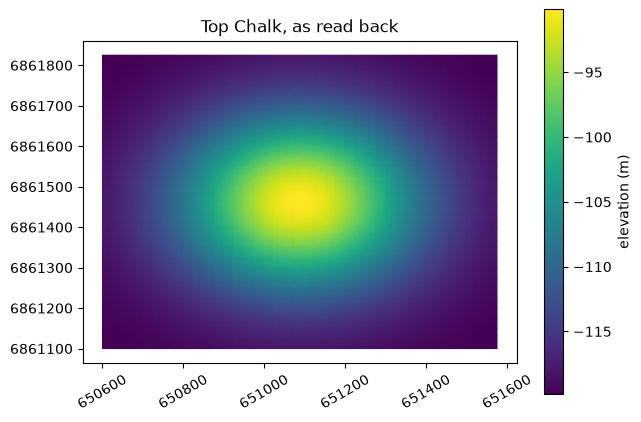

In [10]:
read_points, read_triangles = mesh_of(again, again.uri_of(surface["uuid"]), "projected")
read_points = read_points.reshape(-1, 3)
read_triangles = np.asarray(read_triangles).reshape(-1, 3)
print("points identical:", np.array_equal(read_points, points))
print("triangles identical:", np.array_equal(read_triangles, triangles))

fig, ax = plt.subplots(figsize=(7, 5))
shaded = ax.tripcolor(read_points[:, 0], read_points[:, 1], read_triangles, read_points[:, 2],
                      cmap="viridis", shading="gouraud")
fig.colorbar(shaded, ax=ax, label="elevation (m)")
ax.set_title("Top Chalk, as read back")
ax.ticklabel_format(useOffset=False, style="plain")
ax.tick_params(axis="x", labelrotation=30)
ax.set_aspect("equal")
plt.show()

## The other notebooks

- [00 - What is in this package?](00-what-is-in-a-package.ipynb)
- [01 - Geometry, from 2D grids to 3D cells](01-geometry-in-3d.ipynb)
- [02 - Arrays and properties](02-arrays-and-properties.ipynb)
- [03 - Is this package valid?](03-is-this-package-valid.ipynb)
- [05 - Editing a package](05-editing-a-package.ipynb)
- [06 - Exporting to other tools](06-exporting.ipynb)